In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
import seaborn as sns

In [2]:
resistors_data= pd.read_csv('DATA_SET\RESISTANCE DATA EXP-3 (QCLAB).csv')
resistors_data


,Unnamed: 0,ID,RESISTANCE
0,SAMPLE-1,101,21.7
1,NaN,102,21.6
2,NaN,103,21.3
3,NaN,104,21.6
4,NaN,105,21.7
...,...,...,...
234,NaN,B-238,21.5
235,NaN,B-173,21.6
236,NaN,262,21.7
237,NaN,413,21.5


In [3]:
df= resistors_data.copy()
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  15 non-null     str    
 1   ID          224 non-null    str    
 2   RESISTANCE  223 non-null    float64
dtypes: float64(1), str(2)
memory usage: 5.7 KB


In [4]:
df.rename(columns={'Unnamed: 0': 'Sample_No', 'ID': 'Resistor_ID', 'RESISTANCE': 'Resistance'}, inplace=True)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sample_No    15 non-null     str    
 1   Resistor_ID  224 non-null    str    
 2   Resistance   223 non-null    float64
dtypes: float64(1), str(2)
memory usage: 5.7 KB


In [6]:
# drop the rows with missing values in all columns
df.dropna(how='all', inplace=True)


In [7]:
df

,Sample_No,Resistor_ID,Resistance
0,SAMPLE-1,101,21.7
1,NaN,102,21.6
2,NaN,103,21.3
3,NaN,104,21.6
4,NaN,105,21.7
...,...,...,...
234,NaN,B-238,21.5
235,NaN,B-173,21.6
236,NaN,262,21.7
237,NaN,413,21.5


In [8]:
# create a csv file from df
df.to_csv('resistors_data.csv', index=False)

In [9]:
df["Sample_No"] = df["Sample_No"].ffill()
df

,Sample_No,Resistor_ID,Resistance
0,SAMPLE-1,101,21.7
1,SAMPLE-1,102,21.6
2,SAMPLE-1,103,21.3
3,SAMPLE-1,104,21.6
4,SAMPLE-1,105,21.7
...,...,...,...
234,SAMPLE-15,B-238,21.5
235,SAMPLE-15,B-173,21.6
236,SAMPLE-15,262,21.7
237,SAMPLE-15,413,21.5


In [10]:
df[df["Sample_No"]=="SAMPLE-4"]


,Sample_No,Resistor_ID,Resistance
35,SAMPLE-4,301,21.7
36,SAMPLE-4,302,21.9
37,SAMPLE-4,303,21.4
38,SAMPLE-4,304,22.3
39,SAMPLE-4,305,21.4
40,SAMPLE-4,306,21.5
41,SAMPLE-4,307,21.8
42,SAMPLE-4,308,21.6
43,SAMPLE-4,309,21.6
44,SAMPLE-4,310,21.5


In [11]:
# change sample_no of rows 35 to 49 to "SAMPLE-3"
df.loc[35:49, "Sample_No"] = "SAMPLE-3"

In [12]:
df["Sample_No"].value_counts()

Sample_No
SAMPLE-1     15
SAMPLE-2     15
SAMPLE-3     15
SAMPLE-4     15
SAMPLE-5     15
SAMPLE-6     15
SAMPLE-8     15
SAMPLE-9     15
SAMPLE-10    15
SAMPLE-11    15
SAMPLE-12    15
SAMPLE-13    15
SAMPLE-14    15
SAMPLE-15    15
SAMPLE-7     14
Name: count, dtype: int64

In [13]:
# final clean table
df.info()

<class 'pandas.DataFrame'>
Index: 224 entries, 0 to 238
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sample_No    224 non-null    str    
 1   Resistor_ID  224 non-null    str    
 2   Resistance   223 non-null    float64
dtypes: float64(1), str(2)
memory usage: 15.1 KB


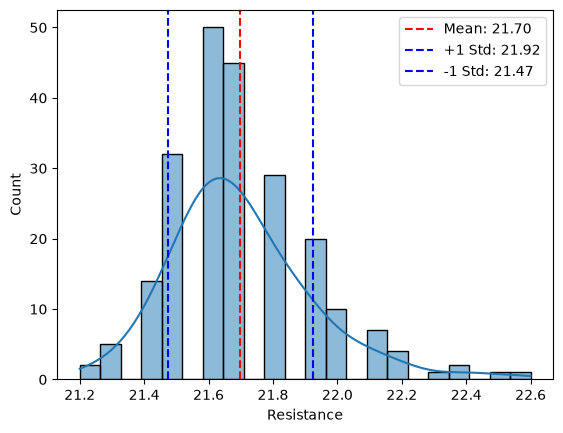

In [22]:
sns.histplot(data=df, x="Resistance", kde=True,  alpha=0.5)
# add mean and std in the legend
mean = df["Resistance"].mean()
std = df["Resistance"].std()

plt.axvline(mean, color='red', linestyle='--', label=f'Mean: {mean:.2f}')
plt.axvline(mean + std, color='blue', linestyle='--', label=f'+1 Std: {mean + std:.2f}')
plt.axvline(mean - std, color='blue', linestyle='--', label=f'-1 Std: {mean - std:.2f}')

plt.legend()

In [15]:
df_grouped= df[["Resistance", "Sample_No"]].groupby("Sample_No").mean()
df_grouped.reset_index(inplace=True)
df_grouped.sort_values(by="Sample_No", ascending=False, inplace=True)

In [23]:
df_grouped.shape

(15, 2)

C:\Users\Mayukh Basak\AppData\Local\Temp\ipykernel_12560\690456623.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df_grouped, x="Resistance",kde=True, palette="Set2", alpha=0.5)


<Axes: xlabel='Resistance', ylabel='Count'>

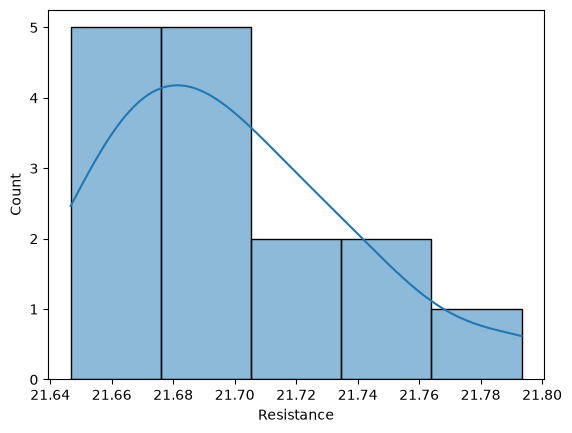

In [16]:
sns.histplot(data=df_grouped, x="Resistance",kde=True, palette="Set2", alpha=0.5)

([0], [Text(0, 0, '')])

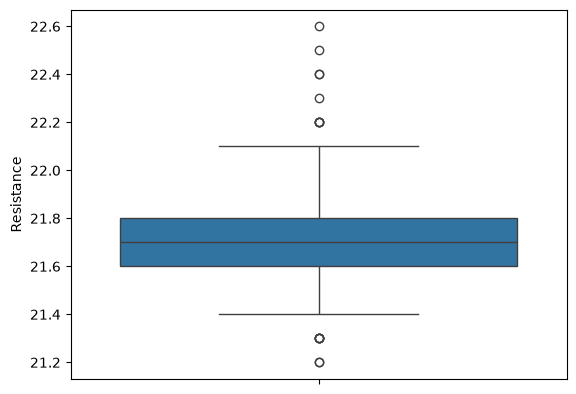

In [17]:
sns.boxplot(data=df,  y="Resistance")
plt.xticks(rotation=45)

In [18]:
# detect the outliers in the Resistance column using IQR method
Q1 = df["Resistance"].quantile(0.25)
Q3 = df["Resistance"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df_outliers = df[(df["Resistance"] < lower_bound) | (df["Resistance"] > upper_bound)]
df_outliers


,Sample_No,Resistor_ID,Resistance
2,SAMPLE-1,103,21.3
38,SAMPLE-3,304,22.3
61,SAMPLE-4,B-117,22.2
74,SAMPLE-5,B-199,21.2
77,SAMPLE-5,B-169,22.2
88,SAMPLE-6,B-134,22.4
113,SAMPLE-8,404,21.3
133,SAMPLE-9,509,21.3
137,SAMPLE-9,513,22.2
164,SAMPLE-11,708,21.2


In [19]:
print("Skewness of Resistance:", df["Resistance"].skew())

print("Kurtosis of Resistance:", df["Resistance"].kurt())

Skewness of Resistance: 0.9281215716254091
Kurtosis of Resistance: 1.7460167821273664


In [20]:
df["Resistance"].describe()

count    223.000000
mean      21.699103
std        0.225011
min       21.200000
25%       21.600000
50%       21.700000
75%       21.800000
max       22.600000
Name: Resistance, dtype: float64

In [21]:
df_grouped

,Sample_No,Resistance
14,SAMPLE-9,21.646667
13,SAMPLE-8,21.660000
12,SAMPLE-7,21.678571
11,SAMPLE-6,21.746667
10,SAMPLE-5,21.700000
9,SAMPLE-4,21.740000
8,SAMPLE-3,21.666667
7,SAMPLE-2,21.666667
6,SAMPLE-15,21.693333
5,SAMPLE-14,21.686667
